 # VQE Study of the Transverse-Field Ising Chain



 This notebook preserves the 2026–2027 TensorCircuit/TensorFlow tutorial circuit family and Adam workflow (Hadamard initialization, nearest-neighbour $ZZ$ entanglers, sitewise $R_x$ rotations) and extends it with repeated-seed size scaling, field sweeps, circuit-depth sweeps, optimizer sensitivity grids, and statevector memory lower bounds. The verbatim instructor notebook is preserved in `notebooks/tutorial_source/`.



 **Tutorial alignment fix:** In the original `VQE_TFIM.ipynb` tutorial, `exact_energy_tf` passed `h=1.0` (`bx=1.0`), `dmrg_energy` used `bx=0.5`, and `vqe_energy` used a negative $ZZ$ coefficient (`-J/4`). This aligned notebook standardizes Exact Diagonalization, DMRG, and VQE to the exact same spin-$1/2$ antiferromagnetic Hamiltonian (`+J/4` for $ZZ$, `-Jg/2` for $X$, matching Quimb's `j=+1`, `bx=J*g`). All runs are classical CPU statevector simulations.

 ## 1. Execution environment



 Records the interpreter, CPU/RAM specifications, package versions, and TensorFlow compute devices into `results/tutorial_faithful/vqe_environment_record.json`.

In [1]:
from pathlib import Path
import csv, json, os, platform, sys, time, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import quimb.tensor as qtn
import tensorcircuit as tc
import tensorflow as tf

tc.set_backend("tensorflow")
tc.set_dtype("complex64")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "tutorial_faithful"
try:
    EXECUTABLE_LABEL = str(Path(sys.executable).resolve().relative_to(ROOT.resolve()))
except ValueError:
    EXECUTABLE_LABEL = Path(sys.executable).name
RESULTS.mkdir(parents=True, exist_ok=True)
PROCESS = psutil.Process()

def package_version(name):
    if name == "tensorcircuit":
        return getattr(tc, "__version__", "imported; version unavailable")
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

environment = {
    "timestamp_local": time.strftime("%Y-%m-%d %H:%M:%S %z"),
    "python": sys.version,
    "python_executable": EXECUTABLE_LABEL,
    "architecture": platform.architecture()[0],
    "platform": platform.platform(),
    "cpu_model": platform.processor() or "not reported by platform.processor()",
    "physical_cpus": psutil.cpu_count(logical=False),
    "logical_cpus": psutil.cpu_count(logical=True),
    "installed_ram_gib": round(psutil.virtual_memory().total / 2**30, 2),
    "available_ram_gib_at_start": round(psutil.virtual_memory().available / 2**30, 2),
    "tensorflow_version": tf.__version__,
    "tensorflow_devices": [d.name for d in tf.config.list_physical_devices()],
    "tensorflow_gpu_devices": [d.name for d in tf.config.list_physical_devices("GPU")],
    "gpu_model": (
        "TensorFlow GPU devices: " + ", ".join(d.name for d in tf.config.list_physical_devices("GPU"))
        if tf.config.list_physical_devices("GPU")
        else "No GPU device exposed to TensorFlow."
    ),
    "packages": {
        p: package_version(p)
        for p in ["numpy", "scipy", "matplotlib", "pandas", "psutil", "quimb", "tensorcircuit", "tensorflow"]
    },
    "notes": "Exact diagonalization uses Quimb dense operators, so qibo is not required.",
}
(RESULTS / "vqe_environment_record.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print(json.dumps(environment, indent=2))


{
  "timestamp_local": "2026-11-23 10:41:52 +0100",
  "python": "3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]",
  "python_executable": ".venv\\Scripts\\python.exe",
  "architecture": "64bit",
  "platform": "Windows-10-10.0.19045-SP0",
  "cpu_model": "Intel64 Family 6 Model 186 Stepping 2, GenuineIntel",
  "physical_cpus": 12,
  "logical_cpus": 16,
  "installed_ram_gib": 15.72,
  "available_ram_gib_at_start": 5.05,
  "tensorflow_version": "2.21.0",
  "tensorflow_devices": [
    "/physical_device:CPU:0"
  ],
  "tensorflow_gpu_devices": [],
  "gpu_model": "No GPU device exposed to TensorFlow.",
  "packages": {
    "numpy": "2.5.5",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "pandas": "3.1.1",
    "psutil": "7.2.2",
    "quimb": "1.16.0",
    "tensorcircuit": "1.10.0",
    "tensorflow": "2.21.0"
  },
  "notes": "Exact diagonalization uses Quimb dense operators, so qibo is not required."
}


 ## 2. Hamiltonian, circuit ansatz, and objective



 Each circuit prepares $|+\rangle^{\otimes L}$ via Hadamard gates, followed by `n_layers` layers of nearest-neighbour $ZZ$ entanglers and sitewise $R_x$ rotations. Aligned with Quimb's `j=+1` spin-$1/2$ TFIM convention ($H = +J\sum S_i^z S_{i+1}^z - h\sum S_i^x$, $g=h/J$), the variational expectation is:

 $$E(\theta) = +\frac{J}{4}\sum_{i=1}^{L-1}\langle Z_i Z_{i+1}\rangle - \frac{Jg}{2}\sum_{i=1}^{L}\langle X_i\rangle.$$

 Because the optimization landscape is non-convex, finishing a fixed step budget does not guarantee reaching the ground state; energy traces and reference errors provide the convergence evidence.

In [2]:
ZZ_MATRIX = np.kron(tc.gates._z_matrix, tc.gates._z_matrix)

def vqe_energy(params, L, n_layers, J=1.0, g=0.5):
    circuit = tc.Circuit(L)
    params = tc.backend.cast(params, tc.dtypestr)
    for site in range(L):
        circuit.H(site)
    for layer in range(n_layers):
        for site in range(L - 1):
            circuit.exp1(site, site + 1, unitary=ZZ_MATRIX, theta=params[2 * layer, site])
        for site in range(L):
            circuit.rx(site, theta=params[2 * layer + 1, site])

    energy = 0.0
    for site in range(L):
        energy += -(J * g / 2.0) * circuit.expectation((tc.gates.x(), [site]))
    # Positive +J/4 ZZ coupling aligns directly with Quimb's j=+J convention.
    for site in range(L - 1):
        energy += +(J / 4.0) * circuit.expectation(
            (tc.gates.z(), [site]), (tc.gates.z(), [site + 1])
        )
    return tc.backend.real(energy)

def train_vqe(L, g, n_layers=2, steps=300, seed=0, J=1.0, learning_rate=0.01, optimizer_name="Adam"):
    tf.keras.utils.set_random_seed(seed)
    params = tf.Variable(tf.random.normal([2 * n_layers, L], stddev=0.1))
    if optimizer_name == "Adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate)
    elif optimizer_name == "SGD":
        optimizer = tf.keras.optimizers.SGD(learning_rate)
    else:
        raise ValueError("Choose a declared optimizer: Adam or SGD")
    energies, grad_norms = [], []
    started = time.perf_counter()
    for step in range(steps):
        with tf.GradientTape() as tape:
            energy = vqe_energy(params, L, n_layers, J=J, g=g)
        gradient = tape.gradient(energy, params)
        if gradient is None:
            raise RuntimeError("TensorFlow returned a missing gradient")
        grad_norms.append(float(tf.linalg.global_norm([gradient]).numpy()))
        optimizer.apply_gradients([(gradient, params)])
        energies.append(float(energy.numpy()))
    return {
        "energy": energies[-1],
        "energies": energies,
        "gradient_norms": grad_norms,
        "elapsed_seconds": time.perf_counter() - started,
    }

PILOT = train_vqe(L=4, g=0.5, n_layers=1, steps=30, seed=0)
print("Pilot final energy:", PILOT["energy"], "seconds:", round(PILOT["elapsed_seconds"], 4))


Pilot final energy: -1.0385308265686035 seconds: 1.1158


 ## 3. Reference energies



 Both `exact_energy` (for $L \le 10$) and `dmrg_energy` (for $L > 10$) evaluate the exact same positive-$J$ Quimb Hamiltonian $H = +J\sum S_i^z S_{i+1}^z - Jg\sum S_i^x$.

In [3]:
def exact_energy(L, g, J=1.0, max_L=10):
    if L > max_L:
        raise ValueError(f"Dense exact diagonalization disabled above L={max_L}; use converged DMRG.")
    H = qtn.MPO_ham_ising(L, j=J, bx=J * g).to_dense()
    return float(np.linalg.eigvalsh(H)[0])

def dmrg_energy(L, g, J=1.0, chi_values=(16, 32, 64), tolerance=1e-8):
    values = []
    for chi in chi_values:
        H = qtn.MPO_ham_ising(L, j=J, bx=J * g)
        solver = qtn.DMRG2(H, bond_dims=[chi])
        solver.solve(tol=tolerance, verbosity=0)
        values.append({"chi": chi, "energy": float(np.real(solver.energy))})
    return values[-1]["energy"], values


 ## 4. Repeated-seed size scaling at the critical field



 Resets `vqe_runs.csv` on a fresh top-to-bottom run to avoid duplicate entries, then evaluates $L \in \{4, 6, 8, 10, 12\}$ at $g=0.5$, 2 layers, 300 Adam steps ($\mathrm{lr}=0.01$), and 3 seeds (`0, 1, 2`).

In [4]:
EXACT_LIMIT = 10
BASE_SIZES = [4, 6, 8, 10, 12]
BASE_G = 0.5
BASE_LAYERS = 2
BASE_STEPS = 300
BASE_SEEDS = [0, 1, 2]
MAX_VQE_L = 20  # explicit workload guard; larger L are tested via limit_search.py

VQE_RUNS_FILE = RESULTS / "vqe_runs.csv"
VQE_RUNS_FILE.unlink(missing_ok=True)

def append_vqe_row(row, filename="vqe_runs.csv"):
    """Append a VQE row safely, expanding CSV headers if later rows add new keys."""
    path = RESULTS / filename
    if not path.exists():
        with path.open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(row))
            writer.writeheader()
            writer.writerow(row)
        return

    with path.open("r", newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        old_fields = reader.fieldnames or []
        old_rows = list(reader)
    fieldnames = old_fields + [field for field in row if field not in old_fields]
    old_rows.append(row)
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(old_rows)

def run_and_log_vqe(L, g, layers, steps, seed, lr=0.01, optimizer_name="Adam", batch="size_seed"):
    started = time.perf_counter()
    available_gib = psutil.virtual_memory().available / 2**30
    estimated_working_gib = 64.0 * (2**L) / 2**30  # heuristic preflight only
    row = {
        "batch": batch, "L": L, "hilbert_dimension": 2**L, "g": g, "layers": layers,
        "steps": steps, "seed": seed, "learning_rate": lr, "optimizer": optimizer_name,
        "complex64_statevector_lower_bound_mib": 8 * (2**L) / 2**20,
        "estimated_working_gib_heuristic": estimated_working_gib,
        "available_gib_before": available_gib,
        "rss_before_mib": PROCESS.memory_info().rss / 2**20,
        "status": "NOT_STARTED", "error": "",
    }
    if L > MAX_VQE_L:
        row["status"] = "SKIPPED_CONFIGURED_L_CAP"
        row["elapsed_seconds"] = 0.0
        append_vqe_row(row)
        return row, None
    if estimated_working_gib > 0.60 * available_gib:
        row["status"] = "SKIPPED_PREFLIGHT_MEMORY_BUDGET"
        row["elapsed_seconds"] = 0.0
        append_vqe_row(row)
        return row, None
    try:
        reference_kind = "exact"
        if L <= EXACT_LIMIT:
            reference = exact_energy(L, g)
        else:
            reference, _ = dmrg_energy(L, g)
            reference_kind = "DMRG (chi=64)"
        run = train_vqe(L, g, layers, steps, seed, learning_rate=lr, optimizer_name=optimizer_name)
        abs_err = abs(run["energy"] - reference)
        row.update({
            "reference_kind": reference_kind,
            "reference_energy": reference,
            "vqe_energy": run["energy"],
            "absolute_error": abs_err,
            "relative_error": abs_err / max(abs(reference), 1e-14),
            "elapsed_seconds": run["elapsed_seconds"],
            "rss_after_mib": PROCESS.memory_info().rss / 2**20,
            "available_gib_after": psutil.virtual_memory().available / 2**30,
            "status": "COMPLETED",
        })
        trace_path = RESULTS / f"trace_L{L}_g{g}_d{layers}_s{seed}_{batch}.csv"
        pd.DataFrame({
            "step": np.arange(1, steps + 1),
            "energy": run["energies"],
            "gradient_norm": run["gradient_norms"],
        }).to_csv(trace_path, index=False)
        append_vqe_row(row)
        return row, run
    except Exception as exc:
        row.update({
            "status": "ERROR",
            "error": f"{type(exc).__name__}: {exc}",
            "elapsed_seconds": time.perf_counter() - started,
            "rss_after_mib": PROCESS.memory_info().rss / 2**20,
            "available_gib_after": psutil.virtual_memory().available / 2**30,
        })
        append_vqe_row(row)
        return row, None

size_rows, size_traces = [], {}
for L in BASE_SIZES:
    for seed in BASE_SEEDS:
        print(f"Running VQE size_seed: L={L}, seed={seed}...", flush=True)
        row, run = run_and_log_vqe(L, BASE_G, BASE_LAYERS, BASE_STEPS, seed, batch="size_seed")
        size_rows.append(row)
        if run is not None:
            size_traces[(L, seed)] = run["energies"]

size_table = pd.DataFrame(size_rows)
size_table.to_csv(RESULTS / "vqe_size_seed_summary.csv", index=False)
size_table


Running VQE size_seed: L=4, seed=0...
Running VQE size_seed: L=4, seed=1...
Running VQE size_seed: L=4, seed=2...
Running VQE size_seed: L=6, seed=0...
Running VQE size_seed: L=6, seed=1...
Running VQE size_seed: L=6, seed=2...
Running VQE size_seed: L=8, seed=0...
Running VQE size_seed: L=8, seed=1...
Running VQE size_seed: L=8, seed=2...
Running VQE size_seed: L=10, seed=0...
Running VQE size_seed: L=10, seed=1...
Running VQE size_seed: L=10, seed=2...
Running VQE size_seed: L=12, seed=0...
Running VQE size_seed: L=12, seed=1...
Running VQE size_seed: L=12, seed=2...


,batch,L,hilbert_dimension,g,layers,steps,seed,learning_rate,optimizer,complex64_statevector_lower_bound_mib,...,status,error,reference_kind,reference_energy,vqe_energy,absolute_error,relative_error,elapsed_seconds,rss_after_mib,available_gib_after
0,size_seed,4,16,0.5,2,300,0,0.01,Adam,0.000122,...,COMPLETED,,exact,-1.189693,-1.188260,0.001432,0.001204,15.870765,502.496094,5.326393
1,size_seed,4,16,0.5,2,300,1,0.01,Adam,0.000122,...,COMPLETED,,exact,-1.189693,-1.188899,0.000793,0.000667,16.045691,505.937500,5.337448
2,size_seed,4,16,0.5,2,300,2,0.01,Adam,0.000122,...,COMPLETED,,exact,-1.189693,-1.186162,0.003530,0.002967,16.410636,508.121094,5.200184
3,size_seed,6,64,0.5,2,300,0,0.01,Adam,0.000488,...,COMPLETED,,exact,-1.824057,-1.794611,0.029447,0.016143,26.216478,511.058594,5.294254
4,size_seed,6,64,0.5,2,300,1,0.01,Adam,0.000488,...,COMPLETED,,exact,-1.824057,-1.800572,0.023485,0.012875,25.701694,511.847656,4.964401
5,size_seed,6,64,0.5,2,300,2,0.01,Adam,0.000488,...,COMPLETED,,exact,-1.824057,-1.803204,0.020854,0.011433,25.662717,511.929688,5.197308
6,size_seed,8,256,0.5,2,300,0,0.01,Adam,0.001953,...,COMPLETED,,exact,-2.459488,-2.392289,0.067199,0.027322,34.765283,514.933594,5.275043
7,size_seed,8,256,0.5,2,300,1,0.01,Adam,0.001953,...,COMPLETED,,exact,-2.459488,-2.415663,0.043825,0.017819,34.835197,516.062500,5.336147
8,size_seed,8,256,0.5,2,300,2,0.01,Adam,0.001953,...,COMPLETED,,exact,-2.459488,-2.401267,0.058221,0.023672,34.735002,516.539062,5.326679
9,size_seed,10,1024,0.5,2,300,0,0.01,Adam,0.007812,...,COMPLETED,,exact,-3.095372,-3.016064,0.079308,0.025622,44.761889,520.542969,5.323284


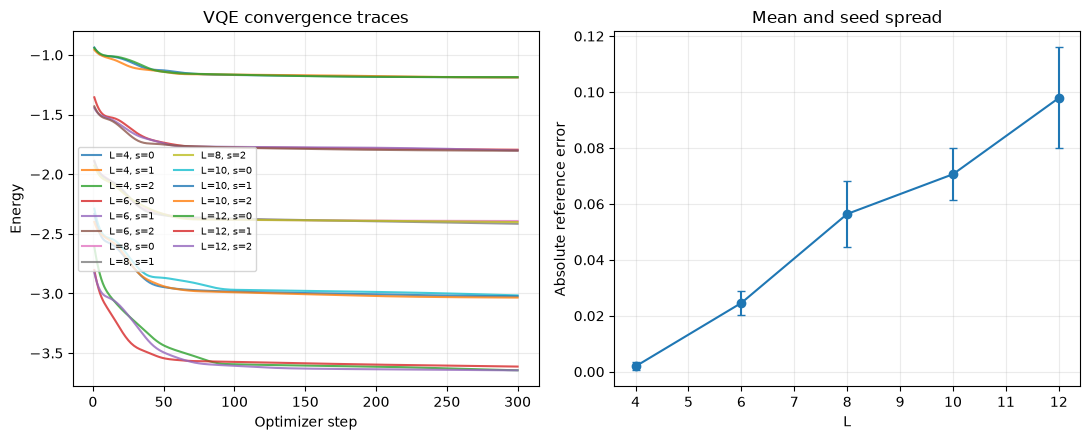

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (L, seed), trace in size_traces.items():
    axes[0].plot(range(1, len(trace) + 1), trace, label=f"L={L}, s={seed}", alpha=0.8)
completed = size_table[size_table.status == "COMPLETED"]
if not completed.empty:
    mean = completed.groupby("L").absolute_error.mean()
    spread = completed.groupby("L").absolute_error.std().fillna(0)
    axes[1].errorbar(mean.index, mean.values, yerr=spread.values, fmt="o-", capsize=3)
axes[0].set(xlabel="Optimizer step", ylabel="Energy", title="VQE convergence traces")
axes[1].set(xlabel="L", ylabel="Absolute reference error", title="Mean and seed spread")
for ax in axes:
    ax.grid(alpha=0.25)
if size_traces:
    axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(RESULTS / "vqe_size_seed_plots.png", dpi=180)
plt.show()


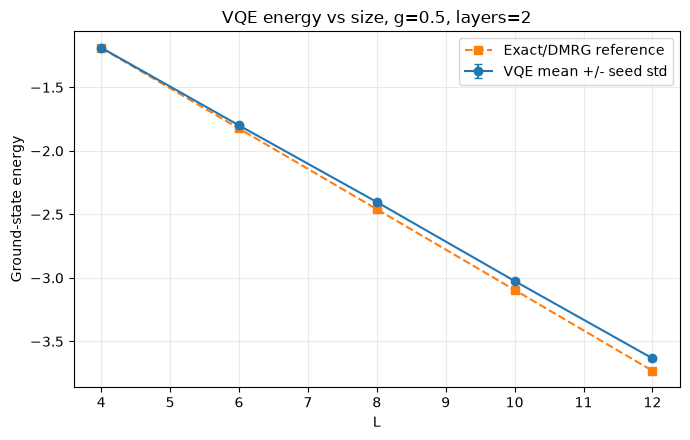

,L,vqe_mean,vqe_std,reference_mean
0,4,-1.187774,0.001432,-1.189693
1,6,-1.799462,0.004403,-1.824057
2,8,-2.403073,0.011791,-2.459488
3,10,-3.024753,0.009208,-3.095372
4,12,-3.633617,0.018058,-3.731493


In [6]:
if not completed.empty:
    energy_summary = completed.groupby("L").agg(
        vqe_mean=("vqe_energy", "mean"),
        vqe_std=("vqe_energy", "std"),
        reference_mean=("reference_energy", "mean"),
    ).reset_index()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.errorbar(
        energy_summary.L, energy_summary.vqe_mean,
        yerr=energy_summary.vqe_std.fillna(0),
        fmt="o-", capsize=3, label="VQE mean +/- seed std",
    )
    ax.plot(energy_summary.L, energy_summary.reference_mean, "s--", label="Exact/DMRG reference")
    ax.set(xlabel="L", ylabel="Ground-state energy", title=f"VQE energy vs size, g={BASE_G}, layers={BASE_LAYERS}")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "vqe_energy_vs_size.png", dpi=180)
    plt.show()
    display(energy_summary)


 ## 5. Field dependence



 At $L=8$, 2 layers, 300 steps, and 3 seeds, this sweep varies $g \in [0.10, 1.00]$ across the ordered, critical ($g_c=0.50$), and field-dominated regimes.

In [7]:
FIELD_L = 8
FIELD_VALUES = [0.10, 0.20, 0.35, 0.45, 0.50, 0.55, 0.65, 0.80, 1.00]
FIELD_SEEDS = [0, 1, 2]
field_rows = []
for g in FIELD_VALUES:
    for seed in FIELD_SEEDS:
        row, _ = run_and_log_vqe(FIELD_L, g, layers=2, steps=300, seed=seed, batch="field_sweep")
        field_rows.append(row)
field_table = pd.DataFrame(field_rows)
field_table.to_csv(RESULTS / "vqe_field_sweep_summary.csv", index=False)
field_table.head()


,batch,L,hilbert_dimension,g,layers,steps,seed,learning_rate,optimizer,complex64_statevector_lower_bound_mib,...,status,error,reference_kind,reference_energy,vqe_energy,absolute_error,relative_error,elapsed_seconds,rss_after_mib,available_gib_after
0,field_sweep,8,256,0.1,2,300,0,0.01,Adam,0.001953,...,COMPLETED,,exact,-1.775077,-1.539467,0.235610,0.132732,35.909453,530.128906,5.330666
1,field_sweep,8,256,0.1,2,300,1,0.01,Adam,0.001953,...,COMPLETED,,exact,-1.775077,-1.553534,0.221542,0.124807,35.236882,530.789062,5.345951
2,field_sweep,8,256,0.1,2,300,2,0.01,Adam,0.001953,...,COMPLETED,,exact,-1.775077,-1.515928,0.259148,0.145993,35.094871,531.289062,5.425156
3,field_sweep,8,256,0.2,2,300,0,0.01,Adam,0.001953,...,COMPLETED,,exact,-1.851398,-1.663230,0.188168,0.101636,35.104853,531.785156,5.424004
4,field_sweep,8,256,0.2,2,300,1,0.01,Adam,0.001953,...,COMPLETED,,exact,-1.851398,-1.672786,0.178611,0.096474,35.199775,532.277344,5.444138


 ## 6. Circuit depth and optimizer settings



 At $L=8$ and $g=0.5$, the depth sweep compares $1\dots 4$ layers and the optimizer grid varies step budget ($\{100, 300, 600\}$) and Adam learning rate ($\{0.001, 0.01, 0.05\}$) across 3 seeds.

In [8]:
SENS_L = 8
DEPTHS = [1, 2, 3, 4]
STEP_COUNTS = [100, 300, 600]
LEARNING_RATES = [0.001, 0.01, 0.05]
SENS_SEEDS = [0, 1, 2]

depth_rows = []
for depth in DEPTHS:
    for seed in SENS_SEEDS:
        row, _ = run_and_log_vqe(SENS_L, 0.5, depth, 300, seed, batch="depth_sweep")
        depth_rows.append(row)
depth_table = pd.DataFrame(depth_rows)
depth_table.to_csv(RESULTS / "vqe_depth_sweep_summary.csv", index=False)

optimizer_rows = []
for steps in STEP_COUNTS:
    for lr in LEARNING_RATES:
        for seed in SENS_SEEDS:
            row, _ = run_and_log_vqe(
                SENS_L, 0.5, layers=2, steps=steps, seed=seed, lr=lr, batch="optimizer_sweep"
            )
            optimizer_rows.append(row)
optimizer_table = pd.DataFrame(optimizer_rows)
optimizer_table.to_csv(RESULTS / "vqe_optimizer_sweep_summary.csv", index=False)
depth_table.head(), optimizer_table.head()


(         batch  L  hilbert_dimension    g  layers  steps  seed  learning_rate  \
 0  depth_sweep  8                256  0.5       1    300     0           0.01   
 1  depth_sweep  8                256  0.5       1    300     1           0.01   
 2  depth_sweep  8                256  0.5       1    300     2           0.01   
 3  depth_sweep  8                256  0.5       2    300     0           0.01   
 4  depth_sweep  8                256  0.5       2    300     1           0.01   
 
   optimizer  complex64_statevector_lower_bound_mib  ...     status  error  \
 0      Adam                               0.001953  ...  COMPLETED          
 1      Adam                               0.001953  ...  COMPLETED          
 2      Adam                               0.001953  ...  COMPLETED          
 3      Adam                               0.001953  ...  COMPLETED          
 4      Adam                               0.001953  ...  COMPLETED          
 
    reference_kind reference_energy 

 ## 7. Statevector scaling and theoretical storage lower bound



 Lists Hilbert-space dimension $2^L$ and raw complex64 / complex128 statevector memory lower bounds. Actual process working-set peak memory (including TensorFlow reverse-mode automatic differentiation intermediates) is measured separately by `limit_search.py`.

In [9]:
L_RANGE = range(4, 25, 2)
statevector_scale = pd.DataFrame({
    "L": list(L_RANGE),
    "hilbert_dimension": [2**L for L in L_RANGE],
    "complex64_statevector_lower_bound_mib": [8 * 2**L / 2**20 for L in L_RANGE],
    "complex128_statevector_lower_bound_mib": [16 * 2**L / 2**20 for L in L_RANGE],
})
statevector_scale.to_csv(RESULTS / "vqe_statevector_lower_bound.csv", index=False)
statevector_scale


,L,hilbert_dimension,complex64_statevector_lower_bound_mib,complex128_statevector_lower_bound_mib
0,4,16,0.000122,0.000244
1,6,64,0.000488,0.000977
2,8,256,0.001953,0.003906
3,10,1024,0.007812,0.015625
4,12,4096,0.031250,0.062500
5,14,16384,0.125000,0.250000
6,16,65536,0.500000,1.000000
7,18,262144,2.000000,4.000000
8,20,1048576,8.000000,16.000000
9,22,4194304,32.000000,64.000000


 ## 8. Automated VQE run summary and limitations



 Summarizes status counts, errors across size/field/depth/optimizer sweeps directly from `vqe_runs.csv`. All simulations are ideal, noise-free classical statevector runs (omitting hardware noise, finite-shot readout variance, and qubit connectivity constraints).

In [10]:
all_vqe = pd.read_csv(RESULTS / "vqe_runs.csv")
print("vqe_runs.csv status counts:", all_vqe.status.value_counts(dropna=False).to_dict())
vqe_done = all_vqe[all_vqe.status == "COMPLETED"]
if not vqe_done.empty:
    print("\nMean absolute error by batch:")
    print(vqe_done.groupby("batch").agg(
        runs=("absolute_error", "count"),
        mean_abs_err=("absolute_error", "mean"),
        max_abs_err=("absolute_error", "max"),
        median_sec=("elapsed_seconds", "median"),
    ).to_string())

vqe_runs.csv status counts: {'COMPLETED': 81}

Mean absolute error by batch:
                 runs  mean_abs_err  max_abs_err  median_sec
batch                                                       
depth_sweep        12      0.049093     0.094696   40.922897
field_sweep        27      0.084881     0.259148   35.156186
optimizer_sweep    27      0.102343     0.399709   60.512316
size_seed          15      0.050285     0.118722   34.765283
